# Classification

## Fixed-Hyperparameter Teaching Version

**If you are a Colab user**

If you use Google Colab, uncomment the following cell to mount your Google Drive. After mounting, Colab can read and write files in your Google Drive.

Please change the current directory to the folder where you saved this notebook and the `Data` folder. For example, the following cell uses a common Colab location.


In [1]:
#from google.colab import drive
#drive.mount('/content/drive')

#%cd /content/drive/MyDrive/Colab\ Notebooks

**Set up standard options for the remainder of the notebook**


In [2]:
## Import libraries and tools ##

import numpy as np
import pandas as pd 

import matplotlib.pyplot as plt 
import seaborn as sns 

import sklearn

import imblearn

# Display multiple outputs in one cell.
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

import warnings
warnings.filterwarnings("ignore")

## The AI4I2020 Predictive Maintenance Dataset

AI4I2020 Predictive Maintenance Dataset

https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset

The dataset contains 10,000 observations. Each row represents one data point, and the columns include identifiers, features, and failure labels:

<ol>
<li>UID: a unique identifier ranging from 1 to 10,000</li>
<li>Product ID: a letter L, M, or H for low, medium, or high product quality, followed by a variant-specific serial number</li>
<li>Type: a categorical product-quality label, L, M, or H</li>
<li>Air temperature [K]: generated using a random-walk process and normalized to a standard deviation of 2 K around 300 K</li>
<li>Process temperature [K]: generated using a random-walk process, normalized to a standard deviation of 1 K, and added to the air temperature plus 10 K</li>
<li>Rotational speed [rpm]: calculated from a power of 2860 W and overlaid with normally distributed noise</li>
<li>Torque [Nm]: normally distributed around 40 Nm with σ = 10 Nm and no negative values</li>
<li>Tool wear [min]: the H, M, and L quality variants add 5, 3, and 2 minutes of tool wear, respectively, during the process</li>
</ol>

The machine-failure label indicates whether the machine failed for any of the following failure modes:

<ol>
<li>Tool wear failure (TWF): the tool is replaced or fails at a randomly selected tool-wear time between 200 and 240 minutes. This occurs 120 times in the dataset. The tool is replaced 69 times and fails 51 times.</li>
<li>Heat dissipation failure (HDF): heat dissipation causes a process failure when the difference between air temperature and process temperature is below 8.6 K and the tool's rotational speed is below 1380 rpm. This occurs for 115 data points.</li>
<li>Power failure (PWF): the product of torque and rotational speed, converted to rad/s, represents the required process power. If this power is below 3500 W or above 9000 W, the process fails. This occurs 95 times in the dataset.</li>
<li>Overstrain failure (OSF): the process fails if the product of tool wear and torque exceeds 11,000 minNm for the L product variant, 12,000 minNm for M, or 13,000 minNm for H. This occurs for 98 data points.</li>
<li>Random failures (RNF): each process has a 0.1% chance of failure regardless of process parameters. This occurs for 5 data points.</li>
</ol>

If at least one of these failure modes is true, the process fails and the `Machine failure` label is set to 1. Therefore, the machine-learning method sees whether a failure occurred, but the binary label alone does not show which failure mode caused it.


### Load and understand data

In [3]:
## Read the dataset in CSV format. ##

df = pd.read_csv('Data/ai4i2020.csv')
df.head(10)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
5,6,M14865,M,298.1,308.6,1425,41.9,11,0,0,0,0,0,0
6,7,L47186,L,298.1,308.6,1558,42.4,14,0,0,0,0,0,0
7,8,L47187,L,298.1,308.6,1527,40.2,16,0,0,0,0,0,0
8,9,M14868,M,298.3,308.7,1667,28.6,18,0,0,0,0,0,0
9,10,M14869,M,298.5,309.0,1741,28.0,21,0,0,0,0,0,0


In [4]:
# Check variable names, data types, and data size.

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [5]:
# Convert integer-valued numerical features to floating-point type.
df['Tool wear [min]'] = df['Tool wear [min]'].astype('float64')
df['Rotational speed [rpm]'] = df['Rotational speed [rpm]'].astype('float64')

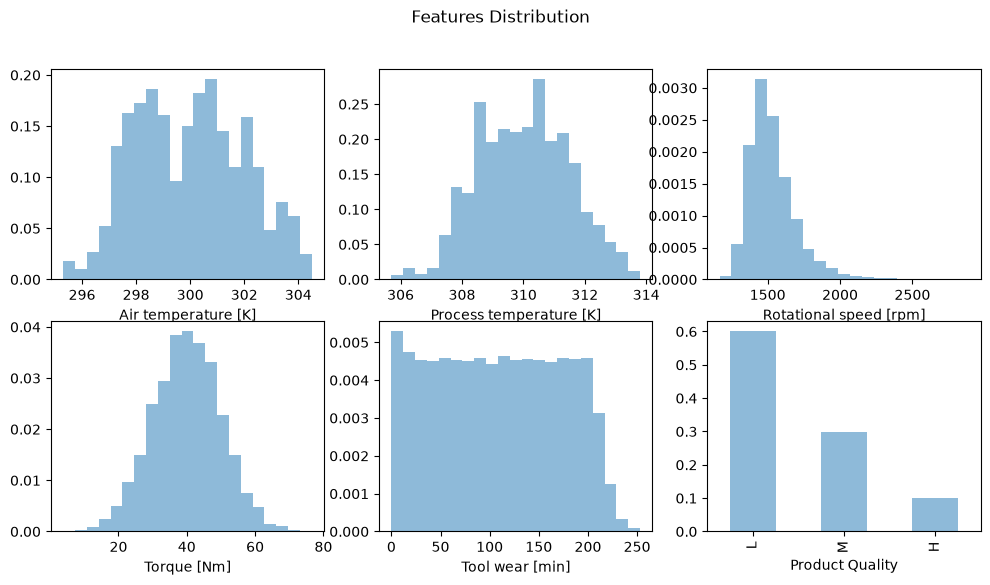

In [6]:
# Visually inspect the features.

features = df.iloc[:,2:8] # Use columns 2-7 from the original dataset as features; there are six features in total.
num_features = features.iloc[:,1:6] # Among these six features, columns 1-5 are numerical and column 0 is categorical.

# Plot histograms of the numeric features.
fig, axs = plt.subplots(nrows=2, 
                        ncols=3, 
                        figsize=(12,6))
fig.suptitle('Features Distribution')
for j, feature in enumerate(num_features):
    row = j//3
    col = j-j//3*3
    axs[row,col].hist(num_features[feature],
                      bins=21,
                      alpha=0.5,
                      density=True)
    axs[row,col].set_xlabel(feature)

# Plot a bar chart of the categorical feature.
type_count = features.Type.value_counts(normalize=True)
type_count.plot(kind='bar',alpha=0.5)
plt.xlabel('Product Quality')

plt.show();


In [7]:
# Review the two target variables: Machine failure and Failure type, recoded from the five failure-type dummy variables.

# Create a new column for failure-mode categories: 0: no failure, 1: TWF, 2: HDF, 3: PWF, 4: OSF, 5: RNF.
# This new column matches the target format expected by scikit-learn.
target = df.iloc[:,8:14]
target['Failure mode']=0 # The default value is 0, meaning no failure.
for i in range(1,6):
    target.loc[(target.iloc[:,i]==1),'Failure mode']=i # Set Failure mode = i if the ith failure type equals 1.

# Check the relationship between `Machine failure` and `Failure mode`.
pd.crosstab(target['Machine failure'],
            target['Failure mode'], 
            values=target['Failure mode'], 
            aggfunc='count')

# Add the derived failure mode as a new column in the dataset.
df['Failure mode']=target['Failure mode']
# There are 9 observations with machine failure but no specified failure mode.
# There are 18 observations with no machine failure but with RNF as the failure mode.
# There is only 1 machine-failure observation whose failure mode is RNF.
# In total, 28 observations appear not to provide useful information for this study, so they can be excluded.

Failure mode,0,1,2,3,4,5
Machine failure,,,,,,
0,9643.0,NaN,NaN,NaN,NaN,18.0
1,9.0,42.0,106.0,83.0,98.0,1.0


### Pre-process data

A few preprocessing steps are required here, including filtering inconsistent observations and rebalancing the data.


#### Data filtering

In [8]:
# Exclude these 28 observations.
obs_excluded = (target['Machine failure']==1)&(target['Failure mode']==0) | (target['Failure mode']==5)
df_proc = df[~obs_excluded]
df_proc

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Failure mode
0,1,M14860,M,298.1,308.6,1551.0,42.8,0.0,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408.0,46.3,3.0,0,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498.0,49.4,5.0,0,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433.0,39.5,7.0,0,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408.0,40.0,9.0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604.0,29.5,14.0,0,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632.0,31.8,17.0,0,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645.0,33.4,22.0,0,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408.0,48.5,25.0,0,0,0,0,0,0,0


In [9]:
# Exclude these 28 observations.
obs_excluded = (target['Machine failure']==1)&(target['Failure mode']==0) | (target['Failure mode']==5)
df_proc = df[~obs_excluded]

# Drop columns that will not be used in this study.
df_proc = df_proc.drop(columns=['UDI','Product ID','TWF','HDF','PWF','OSF','RNF'])

# Check the updated dataset.
df_proc.info()

<class 'pandas.DataFrame'>
Index: 9972 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Type                     9972 non-null   str    
 1   Air temperature [K]      9972 non-null   float64
 2   Process temperature [K]  9972 non-null   float64
 3   Rotational speed [rpm]   9972 non-null   float64
 4   Torque [Nm]              9972 non-null   float64
 5   Tool wear [min]          9972 non-null   float64
 6   Machine failure          9972 non-null   int64  
 7   Failure mode             9972 non-null   int64  
dtypes: float64(5), int64(2), str(1)
memory usage: 701.2 KB


#### Train-validation-test split

In [10]:
# Check the distribution of Failure mode in the filtered dataset.
print('Sample size by class:')
print(df_proc['Failure mode'].value_counts().sort_index())
# Failure samples account for about 3.3% of the dataset, so the dataset is highly imbalanced.

# Separate predictors and responses before any learned preprocessing.
X = df_proc.iloc[:, :-2].copy()
Y = df_proc.iloc[:, -2:].copy()

# Split the original observations into training (80%), validation (10%), and test (10%) sets.
from sklearn.model_selection import train_test_split
rd_state = 0
X_train, X_val_test, Y_train, Y_val_test = train_test_split(
    X, Y, test_size=0.2, stratify=Y['Failure mode'], random_state=rd_state
)
X_val, X_test, Y_val, Y_test = train_test_split(
    X_val_test, Y_val_test, test_size=0.5,
    stratify=Y_val_test['Failure mode'], random_state=rd_state
)

Sample size by class:
Failure mode
0    9643
1      42
2     106
3      83
4      98
Name: count, dtype: int64


#### Data normalization


In [11]:
# Fit the scaler on numerical training features only.
from sklearn.preprocessing import StandardScaler

numeric_features = X_train.select_dtypes(include=np.number).columns
scaler = StandardScaler()
X_train.loc[:, numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_val.loc[:, numeric_features] = scaler.transform(X_val[numeric_features])
X_test.loc[:, numeric_features] = scaler.transform(X_test[numeric_features])
X_train.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
5960,L,0.246537,0.464694,0.374987,-0.653769,0.201223
9421,M,-0.951376,-1.017782,-0.868480,1.452644,-1.423921
7041,L,0.296450,0.329923,-0.379975,-0.232487,-0.158184
9687,M,-0.452246,0.060382,0.613688,-0.844349,-1.048888
5539,H,1.144972,1.138547,-0.313361,-0.102090,0.294982


#### Training-data rebalancing


In [12]:
# Apply SMOTENC only to the training partition.
# `Type` is the only categorical predictor; response columns are not passed as predictors.
from imblearn.over_sampling import SMOTENC

n_neg = (Y_train['Failure mode'] == 0).sum()
n_pcs = round((round(n_neg / 0.8) - n_neg) / 4)
balance_cause = {0: n_neg, 1: n_pcs, 2: n_pcs, 3: n_pcs, 4: n_pcs}

sm = SMOTENC(categorical_features=[0],
             sampling_strategy=balance_cause,
             random_state=rd_state)
X_train, y_train_mode = sm.fit_resample(X_train, Y_train['Failure mode'])

# After inconsistent observations were removed, failure mode determines machine failure.
Y_train = pd.DataFrame({
    'Machine failure': (y_train_mode != 0).astype(int),
    'Failure mode': y_train_mode.astype(int),
}, index=X_train.index)

print('Sample size by class in training data after resampling:')
print(Y_train['Failure mode'].value_counts().sort_index())

Sample size by class in training data after resampling:
Failure mode
0    7714
1     482
2     482
3     482
4     482
Name: count, dtype: int64


#### One-hot encoding of the categorical feature

In [13]:
# Recode `Type` after resampling and use the training columns for all partitions.
X_train = pd.get_dummies(X_train, columns=['Type'], dtype=int)
X_val = pd.get_dummies(X_val, columns=['Type'], dtype=int)
X_test = pd.get_dummies(X_test, columns=['Type'], dtype=int)

X_val = X_val.reindex(columns=X_train.columns, fill_value=0)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print('Training shape:', X_train.shape)
print('Validation shape:', X_val.shape)
print('Test shape:', X_test.shape)
X_train.head()

Training shape: (9642, 8)
Validation shape: (997, 8)
Test shape: (998, 8)


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_H,Type_L,Type_M
0,0.246537,0.464694,0.374987,-0.653769,0.201223,0,1,0
1,-0.951376,-1.017782,-0.868480,1.452644,-1.423921,0,0,1
2,0.296450,0.329923,-0.379975,-0.232487,-0.158184,0,1,0
3,-0.452246,0.060382,0.613688,-0.844349,-1.048888,0,0,1
4,1.144972,1.138547,-0.313361,-0.102090,0.294982,1,0,0


## Evaluation Metrics

In [14]:
# Define the sampling target for each class.evaluation metrics for classification

def eval_pred(model,X,Y,task,disp):
    # model: classification model.
    # X: feature matrix.
    # Y: target labels. labels.
    # task: `binary` or `multi_class`.
    # disp: whether to display results; True or False.
    
    from sklearn import metrics
    from sklearn.metrics import accuracy_score, roc_auc_score, average_precision_score, f1_score, confusion_matrix, roc_curve, auc, precision_recall_curve, PrecisionRecallDisplay

    
    # True response.
    if task == 'binary':
        y_true = Y['Machine failure']
    elif task == 'multi_class':
        y_true = Y['Failure mode']
    else:
        print('task must be either "binary" or "multi_class".')  

    # Predicted class.
    y_pred = model.predict(X) # Predicted label.

    # Probabilistic prediction.
    proba = model.predict_proba(X)
        
    # Confusion matrix.
    cm = confusion_matrix(y_true,y_pred)

    # Classification accuracy.
    acc = accuracy_score(y_true,y_pred)

    # Area under the curve.
    if task == 'binary':
        auc= roc_auc_score(y_true, proba[:,1])
    elif task == 'multi_class':
        auc = roc_auc_score(y_true, 
                            proba, 
                            multi_class='ovr', # Options: {'raise', 'ovr', 'ovo'}; default='raise'.
                            average='weighted') # Options: {'micro', 'macro', 'samples', 'weighted'} or None; default='macro'.
    else:
        print('task must be either "binary" or "multi_class".')  

    # F1 score.
    if task == 'binary':
        f1 = f1_score(y_true, y_pred)
    elif task == 'multi_class':
        f1 = f1_score(y_true, y_pred, average='weighted')
    else:
        print('task must be either "binary" or "multi_class".')  


    
        #proba = model.predict_proba(X)[:,1] # probability of class '1'


    scores = round(pd.Series(data={'ACC':acc, 'AUC':auc, 'F1':f1}),3)
    
    if disp == True:
        # Class names.
        if task =='binary':
            class_names=['Normal','Failure'] # Names of classes.
        elif task=='multi_class':
            class_names=['Normal','TWF','HDF','PWF','OSF'] # Names of classes.
        else:
            print('task must be either "binary" or "multi_class".')  


        # Classification report.
        print('\n Class-level report:')
        print(metrics.classification_report(y_true,y_pred,target_names=class_names))

        print('Task-level report:')
        print(scores,'\n')

        # Print the confusion matrix.
        fig, ax = plt.subplots(figsize=(5,5))
        tick_marks = np.arange(len(class_names))
    
        sns.heatmap(pd.DataFrame(cm), 
                    annot=True, 
                    cmap="YlGnBu" ,
                    fmt='g',
                    xticklabels=class_names,
                    yticklabels=class_names)
    
        ax.xaxis.set_label_position("top")
    
        plt.tight_layout()
        plt.title('Confusion matrix', y=1.1)
        plt.ylabel('True label')
        plt.xlabel('Predicted label')
        plt.show()


        # Show precision-recall and ROC curves only for binary classification.
        if task=='binary':
            # Precision-recall curve and average precision.
            precision, recall, _ = precision_recall_curve(y_true, proba[:,1])
            PrecisionRecallDisplay(precision=precision, recall=recall).plot()
            ap = average_precision_score(y_true, proba[:,1])
            plt.title(f'Precision-Recall Curve (AP={ap:.3f})')

            # ROC curve and AUC.
            FP_rate = dict()
            TP_rate = dict()
            ROC_AUC = dict()
            FP_rate, TP_rate,_ = roc_curve(y_true, proba[:,1])
            roc_auc = metrics.auc(FP_rate, TP_rate)
            plt.figure(figsize=(6,4))
            plt.plot(FP_rate,TP_rate, color="darkorange", lw=2, label="ROC curve (AUC = %0.2f)" % auc)
            plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
            plt.xlim([0.0, 1.0])
            plt.ylim([0.0, 1.05])
            plt.xlabel("False Positive Rate")
            plt.ylabel("True Positive Rate")
            plt.title("Receiver Operating Characteristic (ROC)")
            plt.legend(loc="lower right")
            plt.show()
            print('\n')
        
    return cm, scores

## Model

### Model fitting with fixed hyperparameters

The hyperparameter values below were selected in the separate `06_Classification_CV_Pipeline.ipynb` cross-validation experiment. This notebook uses those values directly so that the focus remains on model fitting, validation, and comparison. The test set is not used to adjust these settings.

In [15]:
# Fit one model with fixed, explicitly stated hyperparameters.

import time

def fit_model(model, X, Y, task):
    if task == 'binary':
        target = Y['Machine failure']
    elif task == 'multi_class':
        target = Y['Failure mode']
    else:
        raise ValueError('task must be either "binary" or "multi_class"')

    start_time = time.time()
    model.fit(X, target)
    train_time = (time.time() - start_time) / 60
    print(f'Training time: {train_time:.3f} min')
    return model

### Model comparison

In [16]:
# Compare models.

def predict_and_evaluate(models,X,Y,models_ids,task):
    # models: list of models for comparison.
    # X: feature matrix.
    # Y: target labels. labels.
    # models_ids: list of model names.
    # task: task type, `binary` or `multi_class`.
    
    cm_dict = {key: np.nan for key in models_ids}
    metrics = pd.DataFrame(columns=models_ids)
    y_pred = pd.DataFrame(columns=models_ids)
    
    for model, model_name in zip(models,models_ids):
        y_pred[model_name] = model.predict(X)
        
        if task == 'binary':
            cm, scores = eval_pred(model,X,Y,task='binary',disp=False)
        elif task == 'multi_class':
            cm, scores = eval_pred(model,X,Y,task='multi_class',disp=False)
        
        cm_dict[model_name] = cm
        metrics[model_name] = scores

    return y_pred, cm_dict, metrics

## Binary Classification

Features:
<ol>
 <li>Air temperature [K]: float64</li>
 <li>Process temperature [K]: float64</li>
 <li>Rotational speed [rpm]: float64</li>
 <li>Torque [Nm]: float64</li>
 <li>Tool wear [min]: float64</li>
 <li>Type_L: int64</li>
 <li>Type_M: int64</li>
 <li>Type_H: int64</li>
</ol>

Response:
<ol>
<li>Machine failure: int64</li>
</ol>


### Logistic Regression

LogisticRegression in Scikit-learn

https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

Training time: 0.001 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       0.98      0.96      0.97       964
     Failure       0.30      0.55      0.39        33

    accuracy                           0.94       997
   macro avg       0.64      0.75      0.68       997
weighted avg       0.96      0.94      0.95       997

Task-level report:
ACC    0.943
AUC    0.912
F1     0.387
dtype: float64 



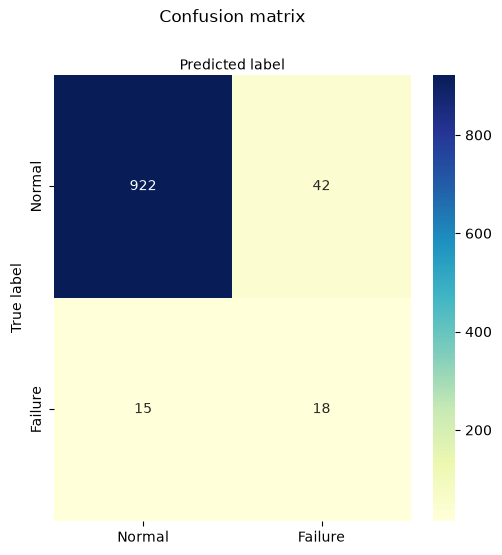

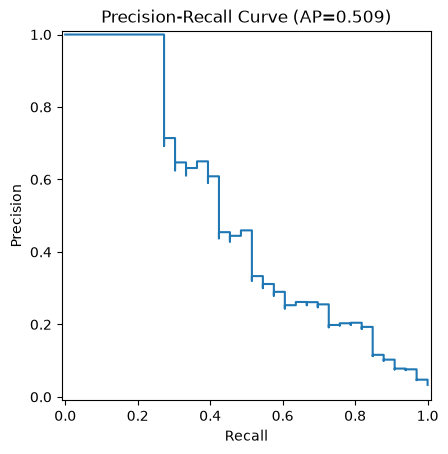

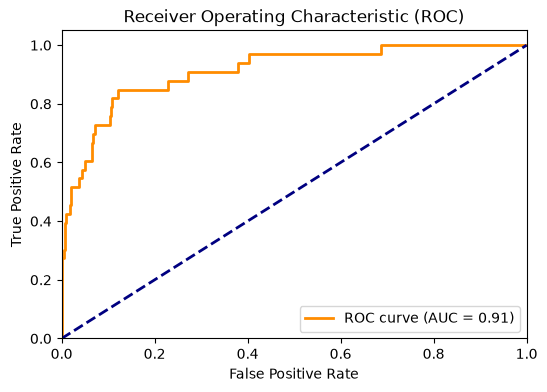

In [17]:
from sklearn.linear_model import LogisticRegression

lgr = LogisticRegression(penalty='elasticnet', C=0.1, l1_ratio=0.1,
                         solver='saga', class_weight=None,
                         max_iter=500, random_state=0)
lgr_model = fit_model(lgr, X_train, Y_train, 'binary')

# Evaluate the model on the validation set.
cm, scores = eval_pred(lgr_model,
                       X_val,
                       Y_val,
                       task='binary',
                       disp=True)

### Linear Discriminant Analysis (LDA)

LinearDiscriminantAnalysis in Scikit-learn

https://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.LinearDiscriminantAnalysis.html

Training time: 0.000 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       0.99      0.96      0.97       964
     Failure       0.35      0.67      0.46        33

    accuracy                           0.95       997
   macro avg       0.67      0.81      0.72       997
weighted avg       0.97      0.95      0.96       997

Task-level report:
ACC    0.948
AUC    0.914
F1     0.458
dtype: float64 



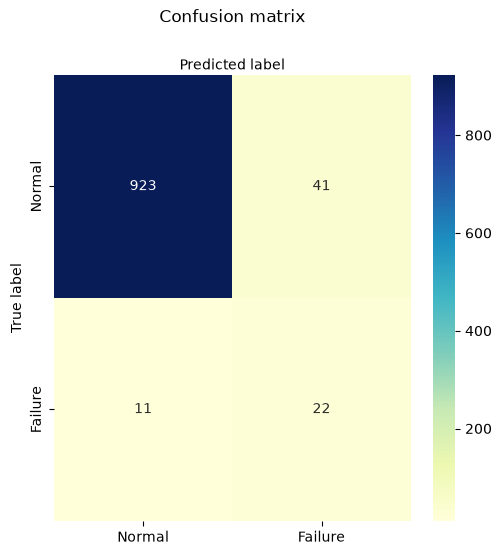

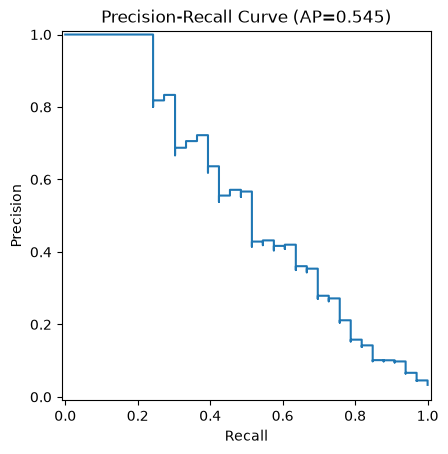

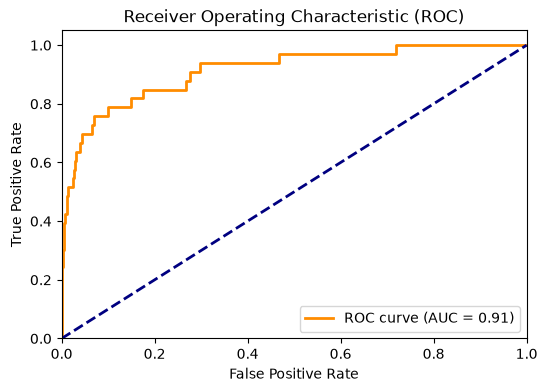

In [18]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(solver='svd')
lda_model = fit_model(lda, X_train, Y_train, 'binary')

# Evaluate the model on the validation set.

cm, scores = eval_pred(lda_model,
                       X_val,
                       Y_val,
                       task='binary',
                       disp=True)


### Quadratic Discriminant Analysis (QDA)

QuadraticDiscriminantAnalysis in Scikit-learn

https://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.QuadraticDiscriminantAnalysis.html


Training time: 0.000 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       0.98      0.95      0.97       964
     Failure       0.27      0.52      0.35        33

    accuracy                           0.94       997
   macro avg       0.63      0.73      0.66       997
weighted avg       0.96      0.94      0.95       997

Task-level report:
ACC    0.938
AUC    0.877
F1     0.354
dtype: float64 



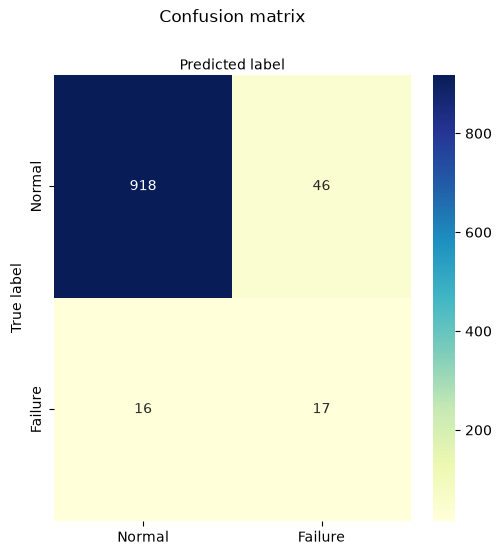

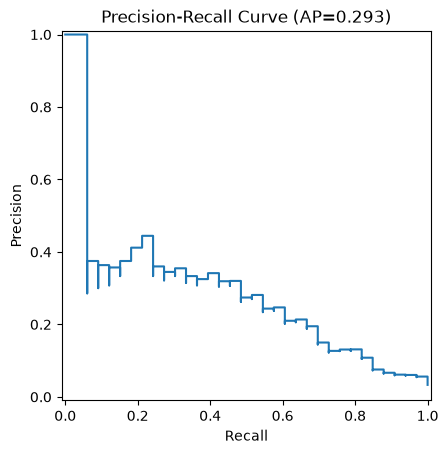

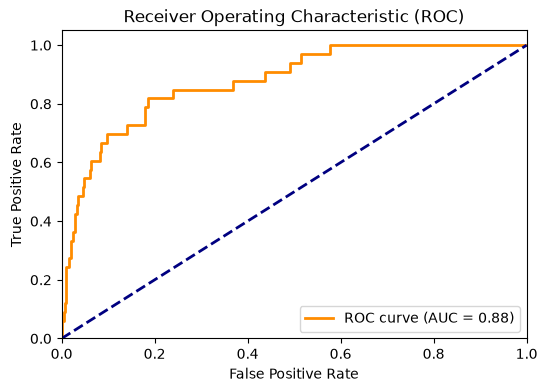

In [19]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

qda = QuadraticDiscriminantAnalysis(reg_param=0.1)
qda_model = fit_model(qda, X_train, Y_train, 'binary')

# Evaluate the model on the validation set.
cm, scores = eval_pred(qda_model,
                       X_val,
                       Y_val,
                       task='binary',
                       disp=True)

### Gaussian Naive Bayes (GNB)

GaussianNB in Scikit-learn: 

https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html

Training time: 0.000 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       0.98      0.77      0.87       964
     Failure       0.09      0.64      0.15        33

    accuracy                           0.77       997
   macro avg       0.54      0.70      0.51       997
weighted avg       0.95      0.77      0.84       997

Task-level report:
ACC    0.767
AUC    0.715
F1     0.153
dtype: float64 



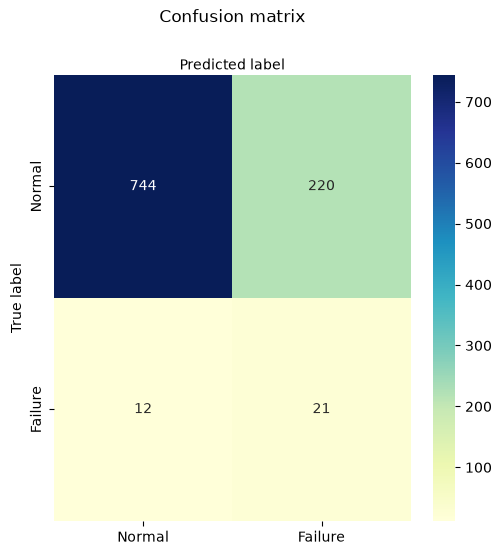

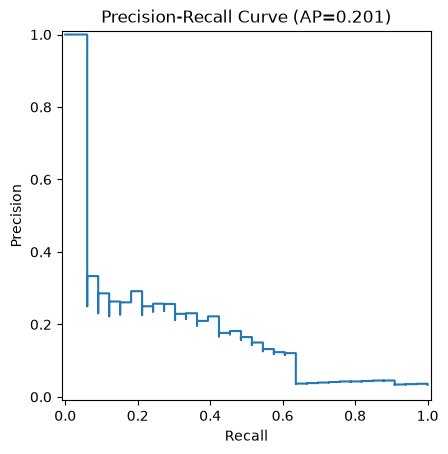

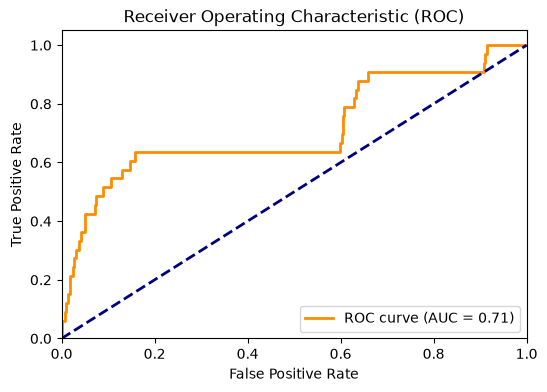

In [20]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB(priors=[0.8, 0.2], var_smoothing=1e-10)
gnb_model = fit_model(gnb, X_train, Y_train, 'binary')

# Evaluate the model on the validation set.
cm, scores = eval_pred(gnb_model,
                       X_val,
                       Y_val,
                       task='binary',
                       disp=True)

### Support Vector Machine (SVM)

SVC in Scikit-learn:

https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html

Training time: 0.038 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       1.00      0.97      0.98       964
     Failure       0.52      0.91      0.66        33

    accuracy                           0.97       997
   macro avg       0.76      0.94      0.82       997
weighted avg       0.98      0.97      0.97       997

Task-level report:
ACC    0.969
AUC    0.984
F1     0.659
dtype: float64 



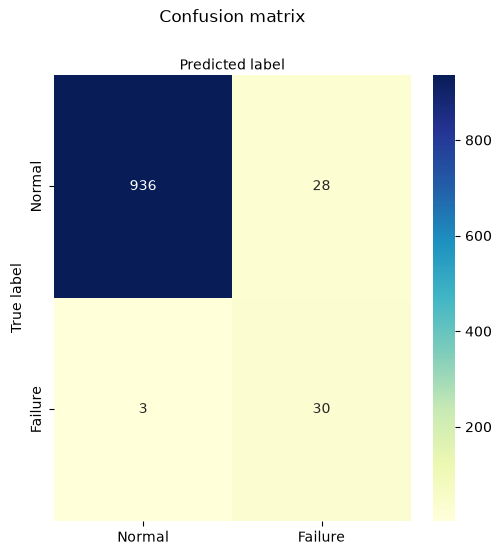

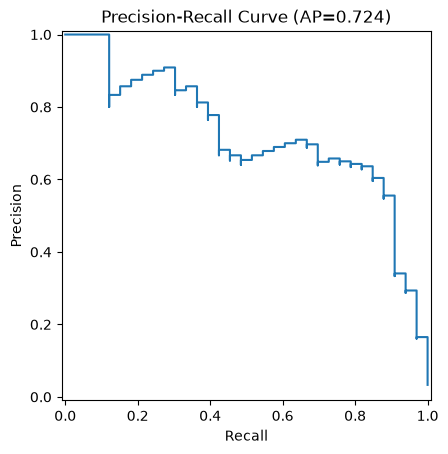

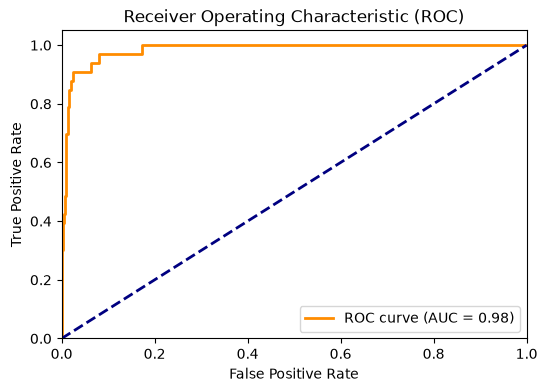

In [21]:
from sklearn.svm import SVC

svm = SVC(C=50, gamma='auto', probability=True,
          class_weight=None, random_state=0)
svm_model = fit_model(svm, X_train, Y_train, 'binary')

# Evaluate the model on the validation set.
cm, scores = eval_pred(svm_model,
                       X_val,
                       Y_val,
                       task='binary',
                       disp=True)


### Decision Tree

DecisionTreeClassifier in Scikit-learn

https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

Training time: 0.000 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99       964
     Failure       0.66      0.82      0.73        33

    accuracy                           0.98       997
   macro avg       0.83      0.90      0.86       997
weighted avg       0.98      0.98      0.98       997

Task-level report:
ACC    0.980
AUC    0.902
F1     0.730
dtype: float64 



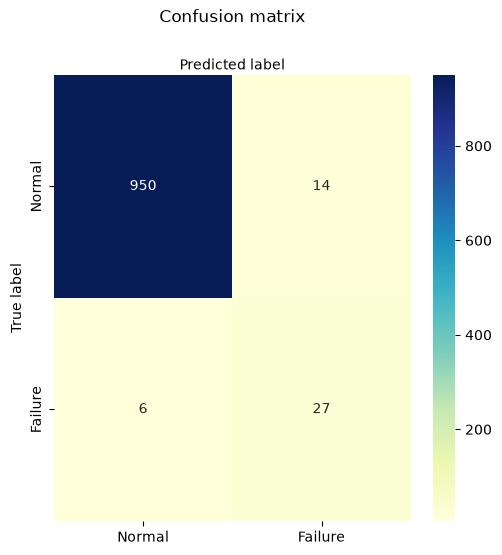

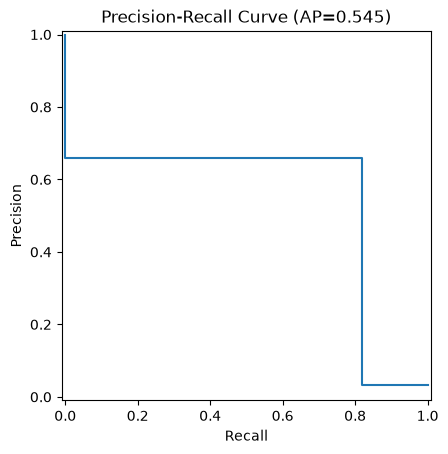

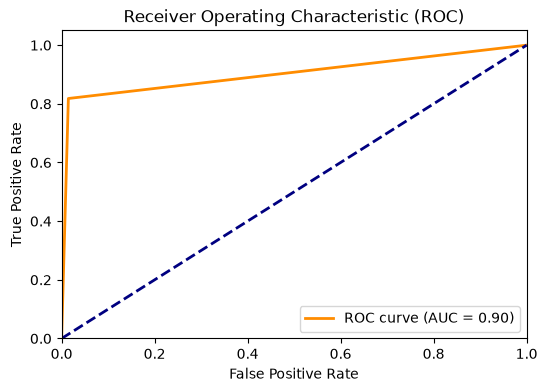

[Text(0.5, 0.875, 'x[2] <= -0.869\nentropy = 0.722\nsamples = 9642\nvalue = [7714, 1928]'),
 Text(0.25, 0.625, 'x[0] <= 0.758\nentropy = 0.997\nsamples = 2010\nvalue = [938, 1072]'),
 Text(0.375, 0.75, 'True  '),
 Text(0.125, 0.375, 'x[3] <= 2.434\nentropy = 0.932\nsamples = 1205\nvalue = [786, 419]'),
 Text(0.0625, 0.125, '\n  (...)  \n'),
 Text(0.1875, 0.125, '\n  (...)  \n'),
 Text(0.375, 0.375, 'x[1] <= 1.204\nentropy = 0.699\nsamples = 805\nvalue = [152, 653]'),
 Text(0.3125, 0.125, '\n  (...)  \n'),
 Text(0.4375, 0.125, '\n  (...)  \n'),
 Text(0.75, 0.625, 'x[4] <= 1.499\nentropy = 0.506\nsamples = 7632\nvalue = [6776, 856]'),
 Text(0.625, 0.75, '  False'),
 Text(0.625, 0.375, 'x[3] <= -2.632\nentropy = 0.279\nsamples = 6745\nvalue = [6420, 325]'),
 Text(0.5625, 0.125, '\n  (...)  \n'),
 Text(0.6875, 0.125, '\n  (...)  \n'),
 Text(0.875, 0.375, 'x[6] <= 0.5\nentropy = 0.972\nsamples = 887\nvalue = [356, 531]'),
 Text(0.8125, 0.125, '\n  (...)  \n'),
 Text(0.9375, 0.125, '\n  (...

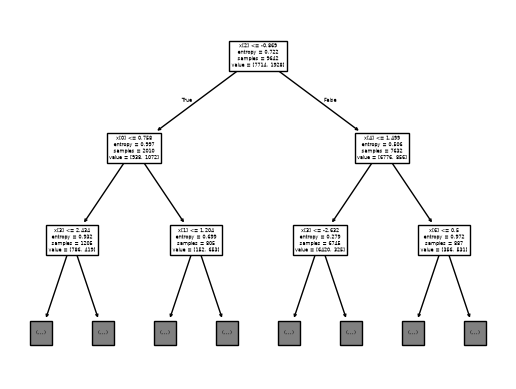

In [22]:
from sklearn.tree import DecisionTreeClassifier

dtc = DecisionTreeClassifier(criterion='entropy', splitter='best',
                             class_weight={0:1, 1:1},
                             max_features=None, random_state=0)
dtc_model = fit_model(dtc, X_train, Y_train, 'binary')


# Evaluate the model on the validation set.
cm, scores = eval_pred(dtc_model,
                       X_val,
                       Y_val,
                       task='binary',
                       disp=True)

from sklearn import tree
tree.plot_tree(dtc_model, max_depth=2)

### Bagging

BaggingClassifier in Scikit-learn

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html

Training time: 0.005 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99       964
     Failure       0.66      0.82      0.73        33

    accuracy                           0.98       997
   macro avg       0.83      0.90      0.86       997
weighted avg       0.98      0.98      0.98       997

Task-level report:
ACC    0.980
AUC    0.963
F1     0.730
dtype: float64 



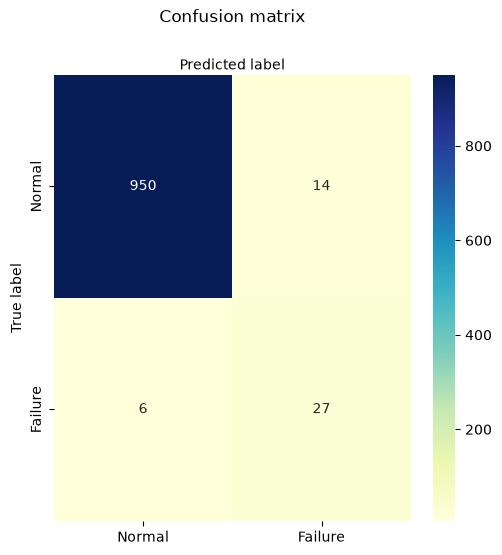

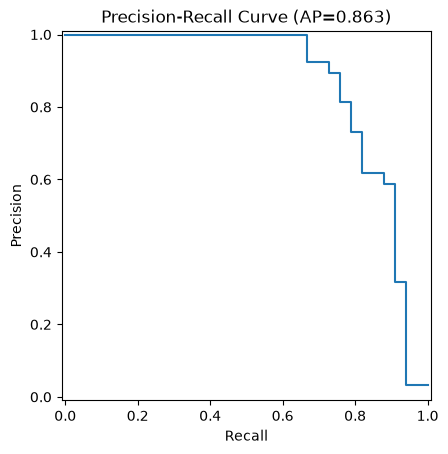

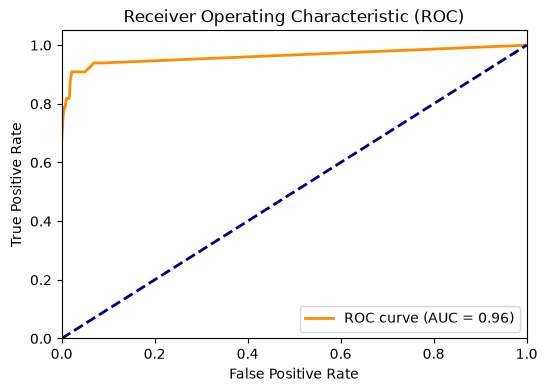

In [23]:
from sklearn.ensemble import BaggingClassifier

bgc = BaggingClassifier(n_estimators=20, random_state=0)
bgc_model = fit_model(bgc, X_train, Y_train, 'binary')

# Evaluate the model on the validation set.
cm, scores = eval_pred(bgc_model,
                       X_val,
                       Y_val,
                       task='binary',
                       disp=True)

### Ada Boosting

AdaBoostClassifier in Scikit-learn

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html

Training time: 0.008 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       0.99      0.97      0.98       964
     Failure       0.41      0.67      0.51        33

    accuracy                           0.96       997
   macro avg       0.70      0.82      0.74       997
weighted avg       0.97      0.96      0.96       997

Task-level report:
ACC    0.957
AUC    0.965
F1     0.506
dtype: float64 



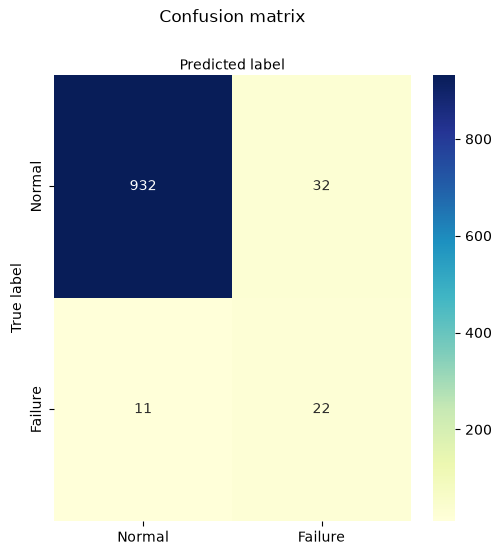

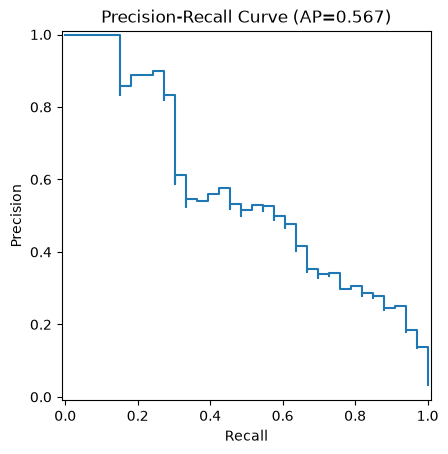

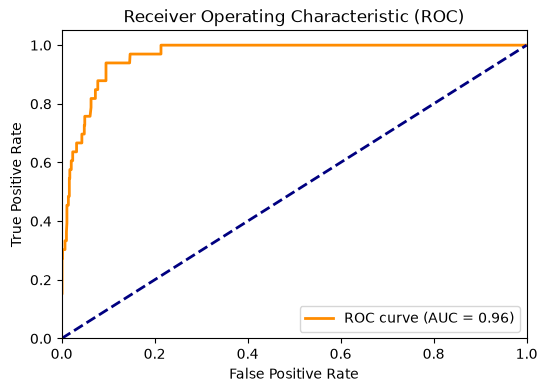

In [24]:
from sklearn.ensemble import AdaBoostClassifier

adb = AdaBoostClassifier(n_estimators=100, learning_rate=1.0, random_state=0)
adb_model = fit_model(adb, X_train, Y_train, 'binary')

# Evaluate the model on the validation set.
cm, scores = eval_pred(adb_model,
                       X_val,
                       Y_val,
                       task='binary',
                       disp=True)

### Gradient Boosting Classifier

GradientBoostingClassifier in Scikit-learn

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html

Training time: 0.033 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       0.99      0.98      0.99       964
     Failure       0.65      0.85      0.74        33

    accuracy                           0.98       997
   macro avg       0.82      0.92      0.86       997
weighted avg       0.98      0.98      0.98       997

Task-level report:
ACC    0.980
AUC    0.991
F1     0.737
dtype: float64 



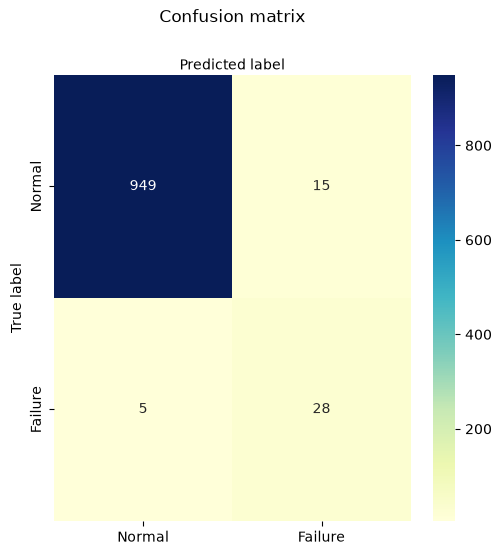

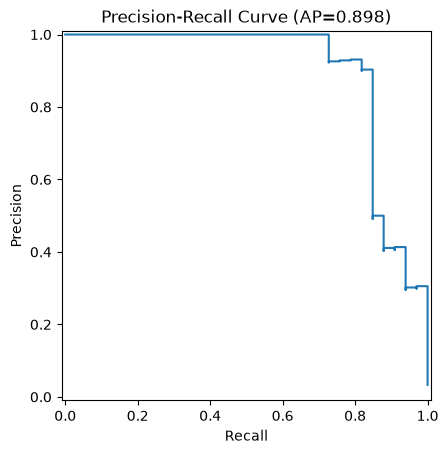

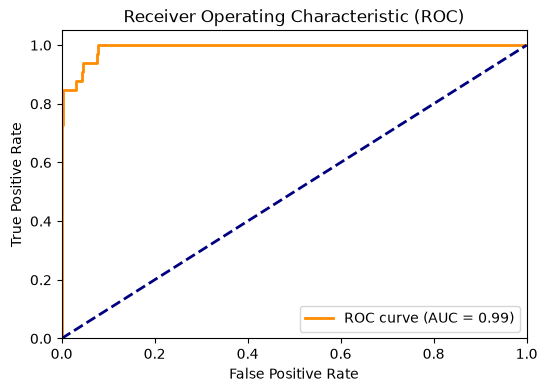

In [25]:
from sklearn.ensemble import GradientBoostingClassifier

gbc = GradientBoostingClassifier(n_estimators=200, learning_rate=0.15, random_state=0)
gbc_model = fit_model(gbc, X_train, Y_train, 'binary')

# Evaluate the model on the validation set.
cm, scores = eval_pred(gbc_model,
                       X_val,
                       Y_val,
                       task='binary',
                       disp=True)

### Random Forest

RandomForestClassifier in Scikit-learn

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

Training time: 0.023 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99       964
     Failure       0.75      0.82      0.78        33

    accuracy                           0.98       997
   macro avg       0.87      0.90      0.89       997
weighted avg       0.99      0.98      0.99       997

Task-level report:
ACC    0.985
AUC    0.963
F1     0.783
dtype: float64 



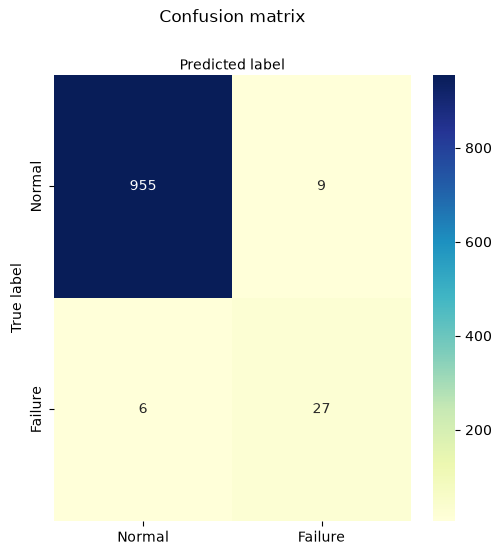

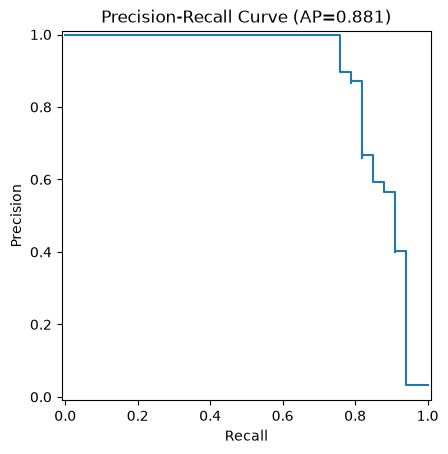

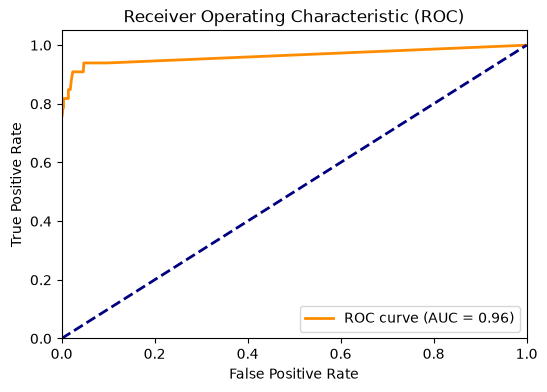

In [26]:
from sklearn.ensemble import RandomForestClassifier

rfc = RandomForestClassifier(n_estimators=100, criterion='log_loss',
                             max_features=None, class_weight=None,
                             random_state=0)
rfc_model = fit_model(rfc, X_train, Y_train, 'binary')

# Evaluate the model on the validation set.
cm, scores = eval_pred(rfc_model,
                       X_val,
                       Y_val,
                       task='binary',
                       disp=True)

### Stacking

StackingClassifier in Scikit-learn

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html

Training time: 0.058 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       0.99      0.98      0.99       964
     Failure       0.57      0.85      0.68        33

    accuracy                           0.97       997
   macro avg       0.78      0.91      0.83       997
weighted avg       0.98      0.97      0.98       997

Task-level report:
ACC    0.974
AUC    0.988
F1     0.683
dtype: float64 



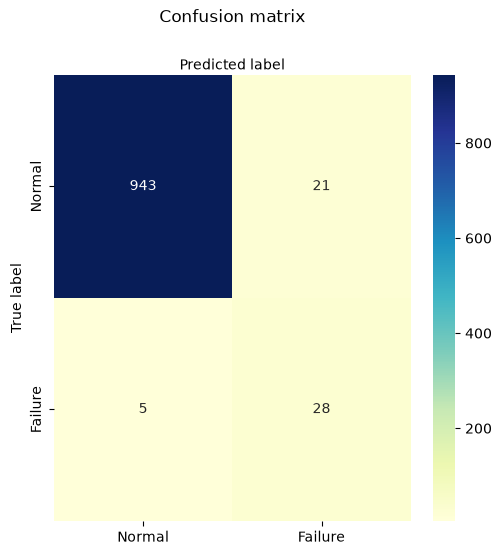

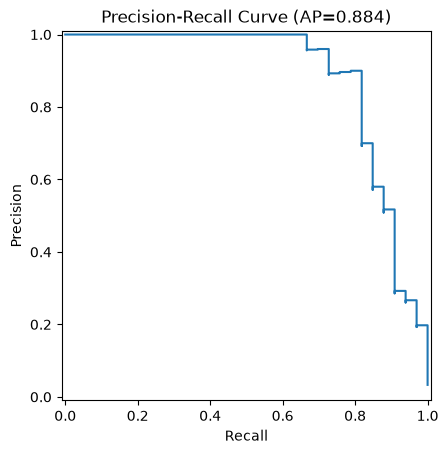

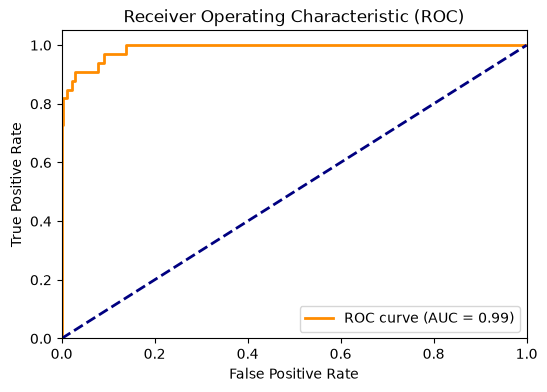

In [27]:
from sklearn.ensemble import StackingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC


estimators = [
    ('rfc', RandomForestClassifier(n_estimators=50, criterion='gini',
                                   max_features=None, random_state=10)),
    ('svm', SVC(C=50, gamma='scale', random_state=10)),
]
stk = StackingClassifier(estimators=estimators,
                         final_estimator=LogisticRegression(max_iter=1000),
                         cv=3)
stk_model = fit_model(stk, X_train, Y_train, 'binary')

# Evaluate the model on the validation set.
cm, scores = eval_pred(stk_model,
                       X_val,
                       Y_val,
                       task='binary',
                       disp=True)

### Comparison on the test dataset

In [28]:
models_ids = ['lgr','lda','qda','gnb','svm','dtc','bgc','adb','gbc','rfc','stk']
models=[lgr_model,lda_model,qda_model,gnb_model,svm_model,dtc_model,bgc_model,adb_model,gbc_model,rfc_model,stk_model]

_, _, scores = predict_and_evaluate(models,
                                    X_test,
                                    Y_test,
                                    models_ids,
                                    'binary')

print('Comparison of clssasification models on the test dataset:')
print(scores)


Comparison of clssasification models on the test dataset:
       lgr    lda    qda    gnb    svm    dtc    bgc    adb    gbc    rfc  \
ACC  0.944  0.946  0.945  0.757  0.966  0.970  0.981  0.962  0.975  0.979   
AUC  0.901  0.909  0.913  0.765  0.960  0.882  0.963  0.963  0.968  0.963   
F1   0.404  0.449  0.382  0.153  0.622  0.634  0.740  0.578  0.675  0.727   

       stk  
ACC  0.975  
AUC  0.974  
F1   0.706  


## Multiclass Classification

Features:
<ol>
 <li>Air temperature [K]: float64</li>
 <li>Process temperature [K]: float64</li>
 <li>Rotational speed [rpm]: float64</li>
 <li>Torque [Nm]: float64</li>
 <li>Tool wear [min]: float64</li>
 <li>Type_L: int64</li>
 <li>Type_M: int64</li>
 <li>Type_H: int64</li>
</ol>

Response:
<ol>
<li>Failure mode: int64</li>
</ol>


### Multinomial Logistic Regression


Training time: 0.007 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       0.99      0.97      0.98       964
         TWF       0.06      0.25      0.09         4
         HDF       0.50      0.90      0.64        10
         PWF       1.00      0.78      0.88         9
         OSF       0.77      1.00      0.87        10

    accuracy                           0.96       997
   macro avg       0.66      0.78      0.69       997
weighted avg       0.98      0.96      0.97       997

Task-level report:
ACC    0.965
AUC    0.984
F1     0.973
dtype: float64 



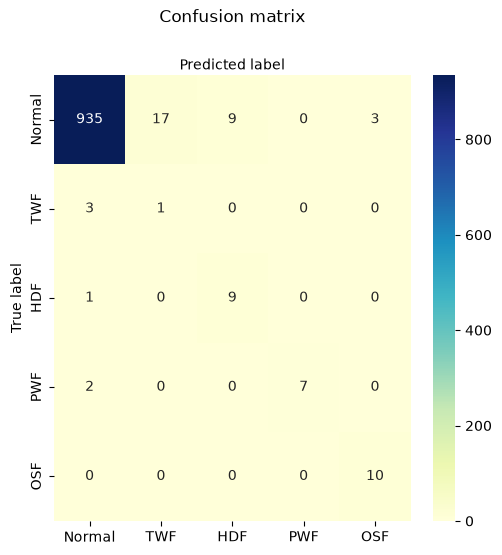

In [29]:
from sklearn.linear_model import LogisticRegression

lgr = LogisticRegression(penalty='elasticnet', C=0.1, l1_ratio=0.9,
                         solver='saga', class_weight=None,
                         max_iter=500, random_state=0)
lgr_model = fit_model(lgr, X_train, Y_train, 'multi_class')

# Evaluate the model on the validation set.
cm, scores = eval_pred(lgr_model,
                       X_val,
                       Y_val,
                       task='multi_class',
                       disp=True)

### Linear Discriminant Analysis (LDA)

Training time: 0.000 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       0.99      0.97      0.98       964
         TWF       0.00      0.00      0.00         4
         HDF       0.33      0.40      0.36        10
         PWF       0.58      0.78      0.67         9
         OSF       0.38      0.80      0.52        10

    accuracy                           0.96       997
   macro avg       0.46      0.59      0.51       997
weighted avg       0.97      0.96      0.96       997

Task-level report:
ACC    0.960
AUC    0.956
F1     0.963
dtype: float64 



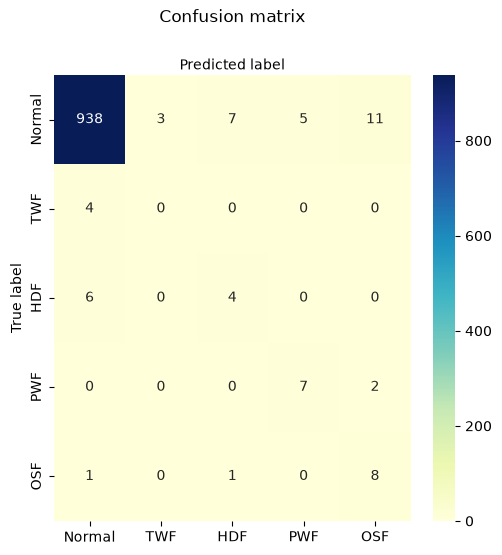

In [30]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(solver='svd')
lda_model = fit_model(lda, X_train, Y_train, 'multi_class')

# Evaluate the model on the validation set.
cm, scores = eval_pred(lda_model,
                       X_val,
                       Y_val,
                       task='multi_class',
                       disp=True)

### Quadratic Discriminant Analysis (QDA)


Training time: 0.000 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       0.98      0.96      0.97       964
         TWF       0.00      0.00      0.00         4
         HDF       0.19      0.30      0.23        10
         PWF       0.12      0.22      0.15         9
         OSF       0.47      0.80      0.59        10

    accuracy                           0.94       997
   macro avg       0.35      0.46      0.39       997
weighted avg       0.96      0.94      0.95       997

Task-level report:
ACC    0.944
AUC    0.943
F1     0.950
dtype: float64 



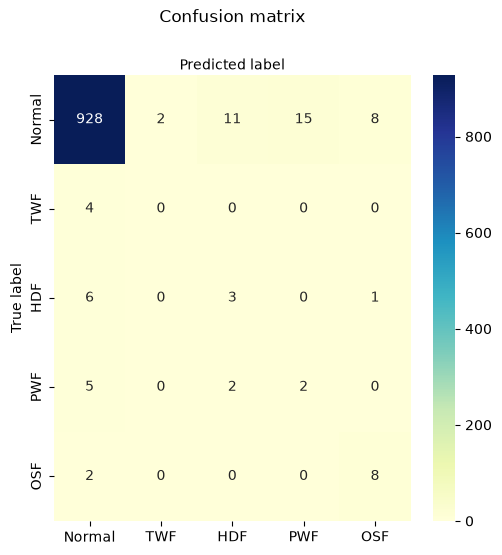

In [31]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

qda = QuadraticDiscriminantAnalysis(reg_param=0.7)
qda_model = fit_model(qda, X_train, Y_train, 'multi_class')

# Evaluate the model on the validation set.
cm, scores = eval_pred(qda_model,
                       X_val,
                       Y_val,
                       task='multi_class',
                       disp=True)

### Gaussian Naive Bayes (GNB)


Training time: 0.000 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       0.99      0.86      0.92       964
         TWF       0.00      0.00      0.00         4
         HDF       0.18      0.60      0.28        10
         PWF       0.04      0.22      0.07         9
         OSF       0.18      0.90      0.30        10

    accuracy                           0.85       997
   macro avg       0.28      0.52      0.31       997
weighted avg       0.96      0.85      0.89       997

Task-level report:
ACC    0.846
AUC    0.813
F1     0.893
dtype: float64 



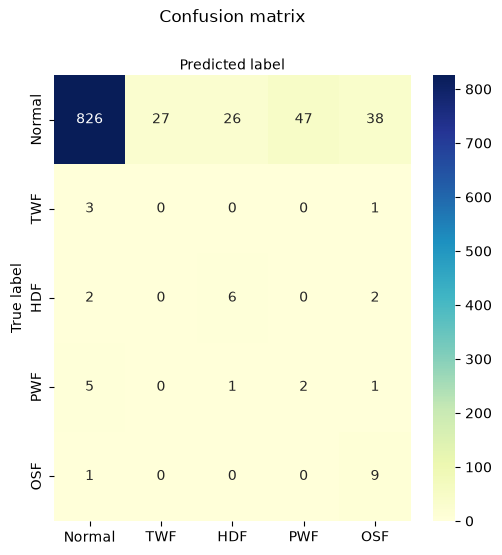

In [32]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB(var_smoothing=1e-7)
gnb_model = fit_model(gnb, X_train, Y_train, 'multi_class')

# Evaluate the model on the validation set.
cm, scores = eval_pred(gnb_model,
                       X_val,
                       Y_val,
                       task='multi_class',
                       disp=True)

### Support Vector Machine (SVM)

Training time: 0.030 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       0.99      0.98      0.99       964
         TWF       0.06      0.25      0.10         4
         HDF       0.75      0.90      0.82        10
         PWF       1.00      0.78      0.88         9
         OSF       1.00      1.00      1.00        10

    accuracy                           0.98       997
   macro avg       0.76      0.78      0.76       997
weighted avg       0.99      0.98      0.98       997

Task-level report:
ACC    0.976
AUC    0.992
F1     0.981
dtype: float64 



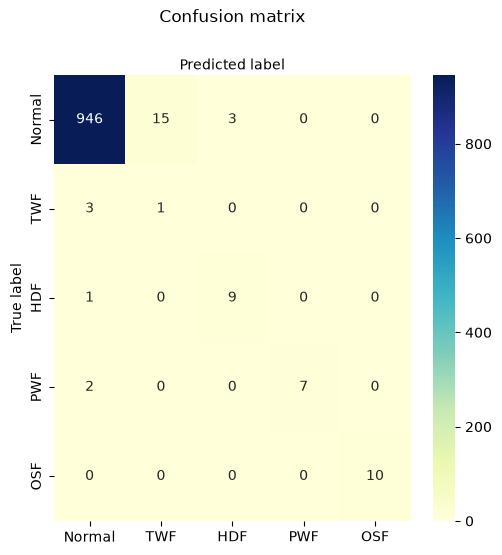

In [33]:
from sklearn.svm import SVC

svm = SVC(C=150, gamma='auto', probability=True,
          class_weight=None, random_state=0)
svm_model = fit_model(svm, X_train, Y_train, 'multi_class')

# Evaluate the model on the validation set.
cm, scores = eval_pred(svm_model,
                       X_val,
                       Y_val,
                       task='multi_class',
                       disp=True)


### Decision Tree

Training time: 0.000 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       0.99      0.98      0.99       964
         TWF       0.00      0.00      0.00         4
         HDF       0.90      0.90      0.90        10
         PWF       1.00      0.89      0.94         9
         OSF       0.75      0.90      0.82        10

    accuracy                           0.98       997
   macro avg       0.73      0.73      0.73       997
weighted avg       0.99      0.98      0.98       997

Task-level report:
ACC    0.977
AUC    0.915
F1     0.982
dtype: float64 



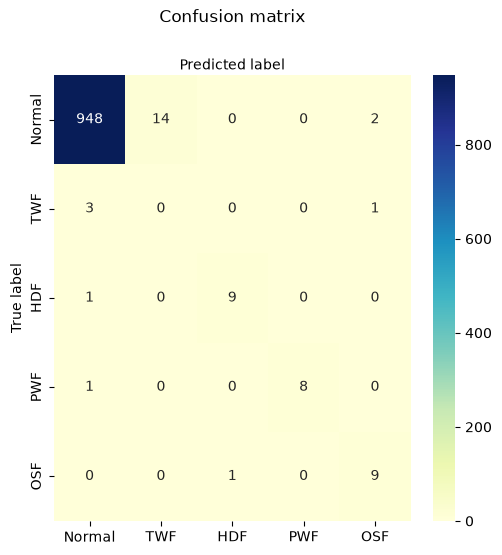

[Text(0.5, 0.875, 'x[4] <= 1.195\ngini = 0.8\nsamples = 9642\nvalue = [1928.4, 1928.4, 1928.4, 1928.4, 1928.4]'),
 Text(0.25, 0.625, 'x[0] <= 0.884\ngini = 0.677\nsamples = 7557\nvalue = [1655.664, 0.0, 1752.363, 1888.392, 96.02]'),
 Text(0.375, 0.75, 'True  '),
 Text(0.125, 0.375, 'x[3] <= 1.909\ngini = 0.541\nsamples = 5621\nvalue = [1308.932, 0.0, 32.007, 1416.294, 92.019]'),
 Text(0.0625, 0.125, '\n  (...)  \n'),
 Text(0.1875, 0.125, '\n  (...)  \n'),
 Text(0.375, 0.375, 'x[2] <= -0.882\ngini = 0.489\nsamples = 1936\nvalue = [346.732, 0.0, 1720.357, 472.098, 4.001]'),
 Text(0.3125, 0.125, '\n  (...)  \n'),
 Text(0.4375, 0.125, '\n  (...)  \n'),
 Text(0.75, 0.625, 'x[3] <= 0.88\ngini = 0.602\nsamples = 2085\nvalue = [272.736, 1928.4, 176.037, 40.008, 1832.38]'),
 Text(0.625, 0.75, '  False'),
 Text(0.625, 0.375, 'x[4] <= 1.405\ngini = 0.289\nsamples = 1453\nvalue = [233.738, 1928.4, 88.018, 40.008, 16.003]'),
 Text(0.5625, 0.125, '\n  (...)  \n'),
 Text(0.6875, 0.125, '\n  (...)  \n

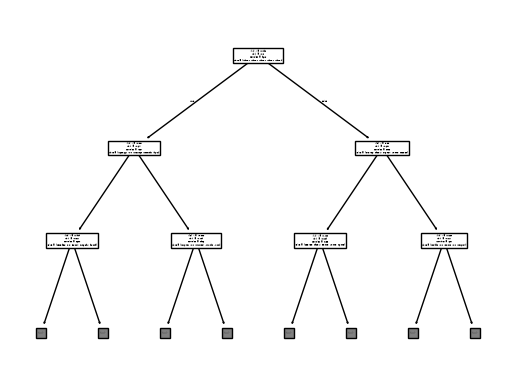

In [34]:
from sklearn.tree import DecisionTreeClassifier # Decision Tree

dtc = DecisionTreeClassifier(criterion='gini', splitter='best',
                             class_weight='balanced',
                             max_features=None, random_state=0)
dtc_model = fit_model(dtc, X_train, Y_train, 'multi_class')

# Evaluate the model on the validation set.
cm, scores = eval_pred(dtc_model,
                       X_val,
                       Y_val,
                       task='multi_class',
                       disp=True)

from sklearn import tree
tree.plot_tree(dtc_model, max_depth=2)

### Bagging

Training time: 0.006 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99       964
         TWF       0.00      0.00      0.00         4
         HDF       1.00      1.00      1.00        10
         PWF       1.00      0.89      0.94         9
         OSF       0.77      1.00      0.87        10

    accuracy                           0.98       997
   macro avg       0.75      0.78      0.76       997
weighted avg       0.99      0.98      0.99       997

Task-level report:
ACC    0.982
AUC    0.977
F1     0.985
dtype: float64 



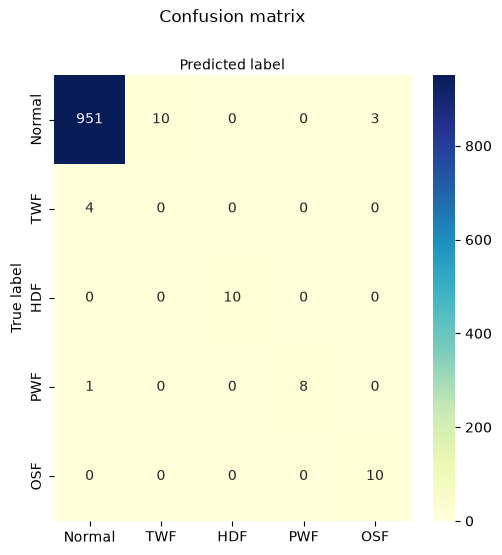

In [35]:
from sklearn.ensemble import BaggingClassifier

bgc = BaggingClassifier(n_estimators=20, random_state=0)
bgc_model = fit_model(bgc, X_train, Y_train, 'multi_class')

# Evaluate the model on the validation set.
cm, scores = eval_pred(bgc_model,
                       X_val,
                       Y_val,
                       task='multi_class',
                       disp=True)

### Ada Boosting

Training time: 0.004 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       0.99      0.97      0.98       964
         TWF       0.08      0.25      0.12         4
         HDF       0.38      0.50      0.43        10
         PWF       0.80      0.44      0.57         9
         OSF       0.47      0.70      0.56        10

    accuracy                           0.96       997
   macro avg       0.54      0.57      0.53       997
weighted avg       0.97      0.96      0.96       997

Task-level report:
ACC    0.958
AUC    0.959
F1     0.963
dtype: float64 



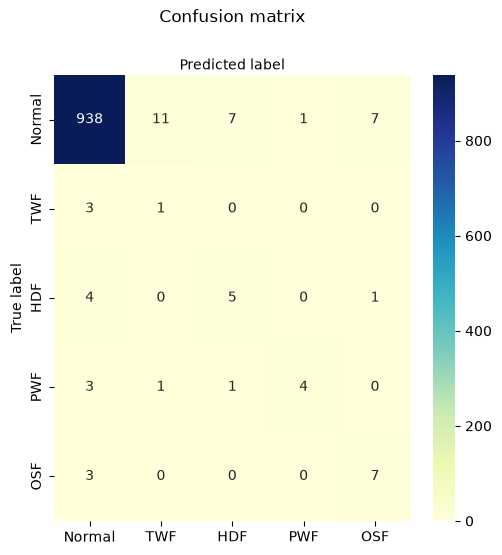

In [36]:
from sklearn.ensemble import AdaBoostClassifier

adb = AdaBoostClassifier(n_estimators=50, learning_rate=1.0, random_state=0)
adb_model = fit_model(adb, X_train, Y_train, 'multi_class')

# Evaluate the model on the validation set.
cm, scores = eval_pred(adb_model,
                       X_val,
                       Y_val,
                       task='multi_class',
                       disp=True)

### Gradient Boosting Classifier

Training time: 0.158 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       964
         TWF       0.00      0.00      0.00         4
         HDF       1.00      1.00      1.00        10
         PWF       1.00      0.89      0.94         9
         OSF       0.77      1.00      0.87        10

    accuracy                           0.99       997
   macro avg       0.75      0.78      0.76       997
weighted avg       0.99      0.99      0.99       997

Task-level report:
ACC    0.992
AUC    0.994
F1     0.991
dtype: float64 



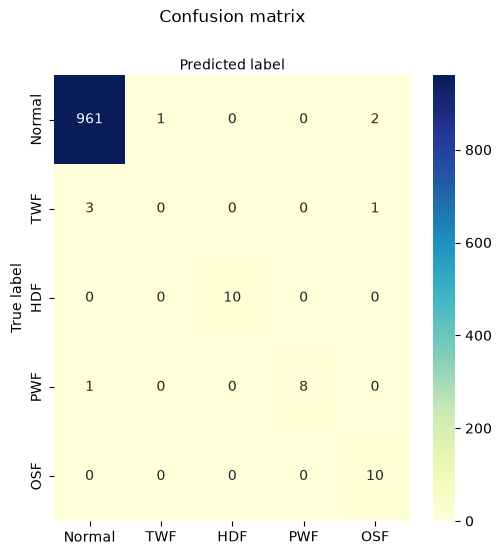

In [37]:
from sklearn.ensemble import GradientBoostingClassifier

gbc = GradientBoostingClassifier(n_estimators=200, learning_rate=0.15, random_state=0)
gbc_model = fit_model(gbc, X_train, Y_train, 'multi_class')

# Evaluate the model on the validation set.
cm, scores = eval_pred(gbc_model,
                       X_val,
                       Y_val,
                       task='multi_class',
                       disp=True)

### Random Forest

Training time: 0.025 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99       964
         TWF       0.00      0.00      0.00         4
         HDF       0.91      1.00      0.95        10
         PWF       1.00      0.89      0.94         9
         OSF       0.83      1.00      0.91        10

    accuracy                           0.98       997
   macro avg       0.75      0.78      0.76       997
weighted avg       0.99      0.98      0.99       997

Task-level report:
ACC    0.985
AUC    0.979
F1     0.987
dtype: float64 



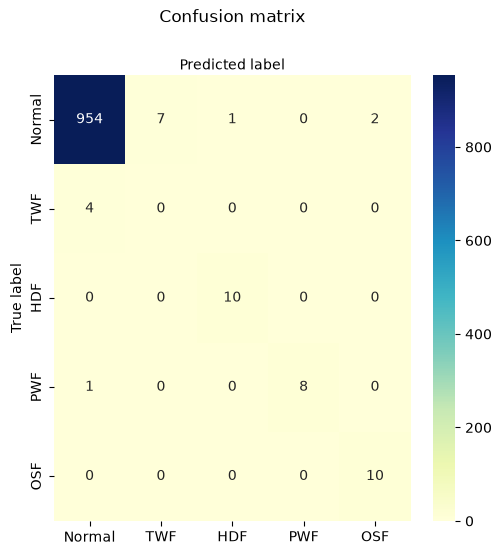

In [38]:
from sklearn.ensemble import RandomForestClassifier

rfc = RandomForestClassifier(n_estimators=100, criterion='log_loss',
                             max_features=None, random_state=0)
rfc_model = fit_model(rfc, X_train, Y_train, 'multi_class')

# Evaluate the model on the validation set.
cm, scores = eval_pred(rfc_model,
                       X_val,
                       Y_val,
                       task='multi_class',
                       disp=True)


### Stacking

Training time: 0.046 min

 Class-level report:
              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99       964
         TWF       0.00      0.00      0.00         4
         HDF       0.90      0.90      0.90        10
         PWF       1.00      1.00      1.00         9
         OSF       0.83      1.00      0.91        10

    accuracy                           0.99       997
   macro avg       0.75      0.78      0.76       997
weighted avg       0.99      0.99      0.99       997

Task-level report:
ACC    0.987
AUC    0.992
F1     0.988
dtype: float64 



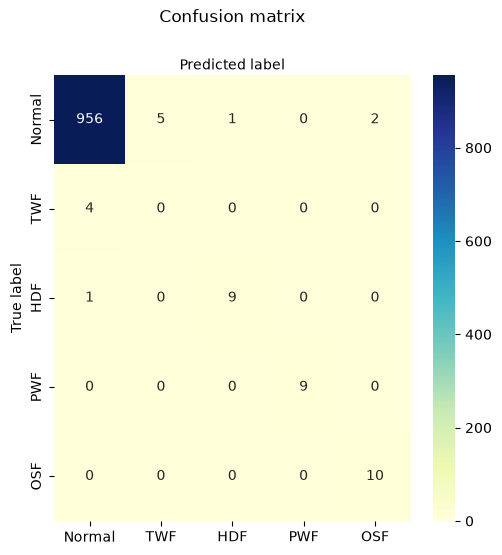

In [39]:
from sklearn.ensemble import StackingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

estimators = [
    ('rfc', RandomForestClassifier(n_estimators=50, criterion='gini',
                                   max_features=None, random_state=10)),
    ('svm', LinearSVC(C=200, penalty='l2', random_state=10)),
]
stk = StackingClassifier(estimators=estimators,
                         final_estimator=LogisticRegression(max_iter=1000),
                         cv=3)
stk_model = fit_model(stk, X_train, Y_train, 'multi_class')


# Evaluate the model on the validation set.
cm, scores = eval_pred(stk_model,
                       X_val,
                       Y_val,
                       task='multi_class',
                       disp=True)

### Comparison on the test dataset

In [40]:
models_ids = ['lgr','lda','qda','gnb','svm','dtc','bgc','adb','gbc','rfc','stk']
fitted_models=[lgr_model,lda_model,qda_model,gnb_model,svm_model,dtc_model,bgc_model,adb_model,gbc_model,rfc_model,stk_model]

y_pred, cm_dict, scores=predict_and_evaluate(fitted_models,
                                             X_test,
                                             Y_test,
                                             models_ids,
                                             'multi_class')

print('Comparison of clssasification models on the test dataset:')
print(scores)


Comparison of clssasification models on the test dataset:
       lgr    lda    qda    gnb    svm    dtc    bgc    adb    gbc    rfc  \
ACC  0.968  0.963  0.958  0.861  0.973  0.976  0.984  0.966  0.984  0.978   
AUC  0.967  0.952  0.956  0.818  0.978  0.856  0.961  0.949  0.984  0.964   
F1   0.973  0.966  0.962  0.902  0.976  0.978  0.985  0.968  0.985  0.981   

       stk  
ACC  0.983  
AUC  0.978  
F1   0.984  
